# DocVQA: per-instance outcome patterns at field=3 vs. its corresponding interpolation scale

This notebook looks at **field value 3** (the added white-border experiment) and compares it
against its corresponding **interpolation scale 3.0** run, on **DocVQA** only, across the same
**4 models** used in the analogous MMVet notebook
(`mmvet_field3_interpolation_pattern_analysis.ipynb`) - the only 4 models with any
field-experiment data at all:

- `llava-hf/llava-1.5-7b-hf`
- `Qwen/Qwen2-VL-7B-Instruct`
- `Qwen/Qwen2.5-VL-7B-Instruct`
- `Qwen/Qwen3-VL-8B-Instruct`

(`meta-llama/Llama-3.2-11B-Vision-Instruct` and `mistral-community/pixtral-12b` are excluded:
neither has ever been run through `main_field.py` on any benchmark, so no field/downsized/
rescaled_back data exists for them anywhere.)

**Assumption:** field and interpolation share the same swept parameter grid
(`0.5, 1, 2, 3, 4, 5`), so "the interpolation size corresponding to field value 3" is taken to be
interpolation scale `3.0`. There's no other explicit mapping between the two sweeps in the
codebase (`src/utils.py:build_field_images`'s per-image `rescaling_coefficient` is image-specific,
not a fixed field-to-scale constant), so this same-numeric-value convention is the only
model-independent correspondence available.

## The 4 experiments (per `src/utils.py:build_field_images` and `main_interpolation.py`)

| name here | source | what it is |
|---|---|---|
| `added_field` | `.../field/DocVQA/..._field3.json` | original image embedded in a larger white-bordered canvas |
| `downsized` | `.../resized/DocVQA/..._resized3.json` | plain original downscaled by the same coefficient the field image experiences during preprocessing |
| `rescaled_back` | `.../bicubic/DocVQA/..._bicubic3.json` | `downsized` scaled back up to the original resolution via bicubic interpolation (detail loss, no size change) |
| `interpolated` | `results_scored_interpolation/.../DocVQA/..._3.0.json` | original image directly resized by a 3.0x multiplicative scale factor |

Each instance also has a **baseline** score at field=0 / scale=1.0 (the untransformed image),
used to split instances into "originally correct" vs. "originally false" before looking at the
4-experiment outcome pattern.

For each instance we build a 4-letter pattern (`C`=correct, `F`=false) in the order
`added_field, downsized, rescaled_back, interpolated` - e.g. `CFCC` means added_field and
rescaled_back and interpolated were correct but downsized was wrong. There are `2**4 = 16`
possible patterns, computed separately within the "originally correct" and "originally false"
groups.

DocVQA is graded with normalized short-answer matching (`src/parse_results.py:score_short_answer`)
rather than MMVet's substring-containment heuristic, so scores here are a more reliable
correct/false signal than in the MMVet version of this notebook.

In [23]:
import sys
from pathlib import Path

project_root = Path().resolve().parent  # notebooks/ -> project root
sys.path.insert(0, str(project_root))

In [24]:
import itertools
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.parse_results import score_example

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

## Models and file locations

The 4 models with a complete `field=3` triplet (added_field/downsized/rescaled_back) on DocVQA, matched against their `results_old` baseline and `results_scored_interpolation` scale=3.0 run.

In [25]:
BENCHMARK = "DocVQA"
FIELD_VALUE = "3"
INTERPOLATION_SCALE = "3.0"

# (results-dir model name, short name used in result filenames, display name)
MODELS = [
    ("llava-hf_llava-1.5-7b-hf", "llava-1.5-7b-hf", "LLaVA-1.5-7B"),
    ("Qwen_Qwen2-VL-7B-Instruct", "Qwen2-VL-7B-Instruct", "Qwen2-VL-7B"),
    ("Qwen_Qwen2.5-VL-7B-Instruct", "Qwen2.5-VL-7B-Instruct", "Qwen2.5-VL-7B"),
    ("Qwen_Qwen3-VL-8B-Instruct", "Qwen3-VL-8B-Instruct", "Qwen3-VL-8B"),
]

RESULTS_DIR = project_root / "results"
RESULTS_OLD_DIR = project_root / "results_old"
INTERPOLATION_SCORED_DIR = project_root / "results_scored_interpolation"


# Load a raw (unscored) result file and return {id: score} for DocVQA.
def load_and_score(path: Path) -> dict:
    with open(path) as f:
        examples = json.load(f)
    scores = {}
    for ex in examples:
        score, _ = score_example(BENCHMARK, ex)
        scores[ex["id"]] = score
    return scores


# Load an already-scored result file and return {id: score}.
def load_scored(path: Path) -> dict:
    with open(path) as f:
        examples = json.load(f)
    return {ex["id"]: ex["score"] for ex in examples}

In [26]:
def model_paths(model_dir: str, short: str) -> dict:
    return {
        "baseline": RESULTS_OLD_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_0.json",
        "added_field": RESULTS_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_field{FIELD_VALUE}.json",
        "downsized": RESULTS_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_resized{FIELD_VALUE}.json",
        "rescaled_back": RESULTS_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_bicubic{FIELD_VALUE}.json",
        "interpolated": INTERPOLATION_SCORED_DIR / model_dir / BENCHMARK / f"{BENCHMARK}_{short}_{INTERPOLATION_SCALE}.json",
    }


EXPERIMENTS = ["added_field", "downsized", "rescaled_back", "interpolated"]

for model_dir, short, display in MODELS:
    for name, path in model_paths(model_dir, short).items():
        assert path.exists(), f"missing {name} file for {display}: {path}"
print("All required files present for all 4 models.")

All required files present for all 4 models.


## Build the per-instance table

Join baseline + the 4 experiments on `id` (DocVQA ids are unique within the 200-sample set, verified below), for every model.

In [27]:
records = []
for model_dir, short, display in MODELS:
    paths = model_paths(model_dir, short)

    baseline_scores = load_and_score(paths["baseline"])
    assert len(baseline_scores) == 200, f"{display}: expected 200 baseline ids, got {len(baseline_scores)}"

    exp_scores = {name: load_and_score(paths[name]) for name in ["added_field", "downsized", "rescaled_back"]}
    exp_scores["interpolated"] = load_scored(paths["interpolated"])

    common_ids = set(baseline_scores)
    for name in EXPERIMENTS:
        common_ids &= set(exp_scores[name])
    assert len(common_ids) == 200, f"{display}: expected 200 common ids, got {len(common_ids)}"

    for sample_id in common_ids:
        row = {
            "model": display,
            "id": sample_id,
            "baseline_score": baseline_scores[sample_id],
        }
        for name in EXPERIMENTS:
            row[name] = exp_scores[name][sample_id]
        records.append(row)

instance_df = pd.DataFrame(records)
print(f"{len(instance_df)} rows ({len(instance_df) // len(MODELS)} instances x {len(MODELS)} models)")
instance_df.head()

800 rows (200 instances x 4 models)


,model,id,baseline_score,added_field,downsized,rescaled_back,interpolated
0,LLaVA-1.5-7B,58726,0.0,0.0,0.0,0.0,0.0
1,LLaVA-1.5-7B,64941,0.0,0.0,0.0,0.0,0.0
2,LLaVA-1.5-7B,57247,0.0,0.0,0.0,0.0,0.0
3,LLaVA-1.5-7B,19226,0.0,0.0,0.0,0.0,0.0
4,LLaVA-1.5-7B,42230,0.0,0.0,0.0,0.0,0.0


## Compute the baseline group and the 16-way outcome pattern

- `baseline_group`: `originally_correct` if the model got the untransformed image right, else `originally_false`.
- `pattern`: a 4-letter `C`/`F` string over `added_field, downsized, rescaled_back, interpolated`, in that order.

In [28]:
def to_letter(score) -> str:
    return "C" if score == 1.0 else "F"


instance_df["baseline_group"] = np.where(
    instance_df["baseline_score"] == 1.0, "originally_correct", "originally_false"
)
instance_df["pattern"] = instance_df[EXPERIMENTS].map(to_letter).agg("".join, axis=1)

ALL_PATTERNS = ["".join(p) for p in itertools.product("CF", repeat=4)]
BASELINE_GROUPS = ["originally_correct", "originally_false"]

instance_df[["model", "id", "baseline_group", "added_field", "downsized", "rescaled_back", "interpolated", "pattern"]].head(10)

,model,id,baseline_group,added_field,downsized,rescaled_back,interpolated,pattern
0,LLaVA-1.5-7B,58726,originally_false,0.0,0.0,0.0,0.0,FFFF
1,LLaVA-1.5-7B,64941,originally_false,0.0,0.0,0.0,0.0,FFFF
2,LLaVA-1.5-7B,57247,originally_false,0.0,0.0,0.0,0.0,FFFF
3,LLaVA-1.5-7B,19226,originally_false,0.0,0.0,0.0,0.0,FFFF
4,LLaVA-1.5-7B,42230,originally_false,0.0,0.0,0.0,0.0,FFFF
5,LLaVA-1.5-7B,58105,originally_false,0.0,0.0,0.0,0.0,FFFF
6,LLaVA-1.5-7B,62471,originally_false,0.0,0.0,0.0,0.0,FFFF
7,LLaVA-1.5-7B,19071,originally_false,0.0,0.0,0.0,0.0,FFFF
8,LLaVA-1.5-7B,8069,originally_false,0.0,0.0,0.0,0.0,FFFF
9,LLaVA-1.5-7B,63698,originally_false,0.0,0.0,0.0,1.0,FFFC


## Summary tables: pattern counts and percentages, split by baseline group

Two distinct tables - one for instances the model originally got **correct**, one for instances it originally got **wrong** - rather than one combined table, so each baseline group can be read on its own.

In [29]:
summary_counts = (
    instance_df.groupby(["model", "baseline_group", "pattern"])
    .size()
    .rename("count")
    .reset_index()
)

# Fill in the full 16-pattern x 2-group grid per model (0 where a pattern never occurs).
full_index = pd.MultiIndex.from_product(
    [[d for _, _, d in MODELS], BASELINE_GROUPS, ALL_PATTERNS],
    names=["model", "baseline_group", "pattern"],
)
summary_counts = (
    summary_counts.set_index(["model", "baseline_group", "pattern"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

group_totals = instance_df.groupby(["model", "baseline_group"]).size().rename("group_total")
summary_counts = summary_counts.join(group_totals, on=["model", "baseline_group"])
summary_counts["pct_of_group"] = (summary_counts["count"] / summary_counts["group_total"] * 100).round(1)

summary_table = summary_counts.pivot_table(
    index=["model", "baseline_group"], columns="pattern", values="pct_of_group"
)[ALL_PATTERNS]

counts_table = summary_counts.pivot_table(
    index=["model", "baseline_group"], columns="pattern", values="count", aggfunc="first"
)[ALL_PATTERNS].astype(int)
counts_table["group_total"] = group_totals.reindex(counts_table.index)

MODEL_ORDER = [d for _, _, d in MODELS]


def for_group(table, group):
    return table.xs(group, level="baseline_group").reindex(MODEL_ORDER)

### Originally correct - % of instances per pattern

In [30]:
pct_originally_correct = for_group(summary_table, "originally_correct")
pct_originally_correct

pattern,CCCC,CCCF,CCFC,CCFF,CFCC,CFCF,CFFC,CFFF,FCCC,FCCF,FCFC,FCFF,FFCC,FFCF,FFFC,FFFF
model,,,,,,,,,,,,,,,,
LLaVA-1.5-7B,20.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.3,0.0,0.0,0.0,0.0,0.0,54.2,16.7
Qwen2-VL-7B,89.2,4.0,1.1,0.0,0.6,1.1,0.0,0.0,0.6,0.6,0.0,0.6,1.7,0.6,0.0,0.0
Qwen2.5-VL-7B,89.7,4.6,1.7,0.0,0.6,0.0,0.0,0.0,1.7,0.0,0.0,0.0,0.6,1.1,0.0,0.0
Qwen3-VL-8B,93.8,1.1,0.0,0.0,1.1,0.0,0.6,0.0,1.7,0.6,0.0,0.0,0.6,0.6,0.0,0.0


### Originally wrong - % of instances per pattern

In [31]:
pct_originally_wrong = for_group(summary_table, "originally_false")
pct_originally_wrong

pattern,CCCC,CCCF,CCFC,CCFF,CFCC,CFCF,CFFC,CFFF,FCCC,FCCF,FCFC,FCFF,FFCC,FFCF,FFFC,FFFF
model,,,,,,,,,,,,,,,,
LLaVA-1.5-7B,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.7,94.3
Qwen2-VL-7B,4.2,0.0,0.0,0.0,0.0,0.0,0.0,4.2,4.2,0.0,4.2,0.0,0.0,0.0,16.7,66.7
Qwen2.5-VL-7B,0.0,4.0,4.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,0.0,4.0,0.0,0.0,24.0,56.0
Qwen3-VL-8B,4.5,0.0,0.0,0.0,0.0,0.0,13.6,0.0,0.0,0.0,4.5,9.1,0.0,0.0,36.4,31.8


### Originally correct - instance counts per pattern

In [32]:
counts_originally_correct = for_group(counts_table, "originally_correct")
counts_originally_correct

pattern,CCCC,CCCF,CCFC,CCFF,CFCC,CFCF,CFFC,CFFF,FCCC,FCCF,FCFC,FCFF,FFCC,FFCF,FFFC,FFFF,group_total
model,,,,,,,,,,,,,,,,,
LLaVA-1.5-7B,5,0,0,0,0,0,0,0,2,0,0,0,0,0,13,4,24
Qwen2-VL-7B,157,7,2,0,1,2,0,0,1,1,0,1,3,1,0,0,176
Qwen2.5-VL-7B,157,8,3,0,1,0,0,0,3,0,0,0,1,2,0,0,175
Qwen3-VL-8B,167,2,0,0,2,0,1,0,3,1,0,0,1,1,0,0,178


### Originally wrong - instance counts per pattern

In [33]:
counts_originally_wrong = for_group(counts_table, "originally_false")
counts_originally_wrong

pattern,CCCC,CCCF,CCFC,CCFF,CFCC,CFCF,CFFC,CFFF,FCCC,FCCF,FCFC,FCFF,FFCC,FFCF,FFFC,FFFF,group_total
model,,,,,,,,,,,,,,,,,
LLaVA-1.5-7B,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,166,176
Qwen2-VL-7B,1,0,0,0,0,0,0,1,1,0,1,0,0,0,4,16,24
Qwen2.5-VL-7B,0,1,1,0,1,0,0,1,0,0,0,1,0,0,6,14,25
Qwen3-VL-8B,1,0,0,0,0,0,3,0,0,0,1,2,0,0,8,7,22


## Save the summary table

Written to the same `results_patterns/` directory used by the MMVet version of this notebook.

In [34]:
out_dir = project_root / "results_patterns"
out_dir.mkdir(exist_ok=True)
out_path = out_dir / "docvqa_field3_interpolation3_pattern_summary.csv"
summary_counts.sort_values(["model", "baseline_group", "pattern"]).to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /home/colligo/Waldo/results_patterns/docvqa_field3_interpolation3_pattern_summary.csv


## Plot: two distributions per model (originally correct vs. originally false)

One bar chart per (model, baseline group), showing how the 200 baseline-group instances split
across the 16 possible `added_field / downsized / rescaled_back / interpolated` outcome patterns.

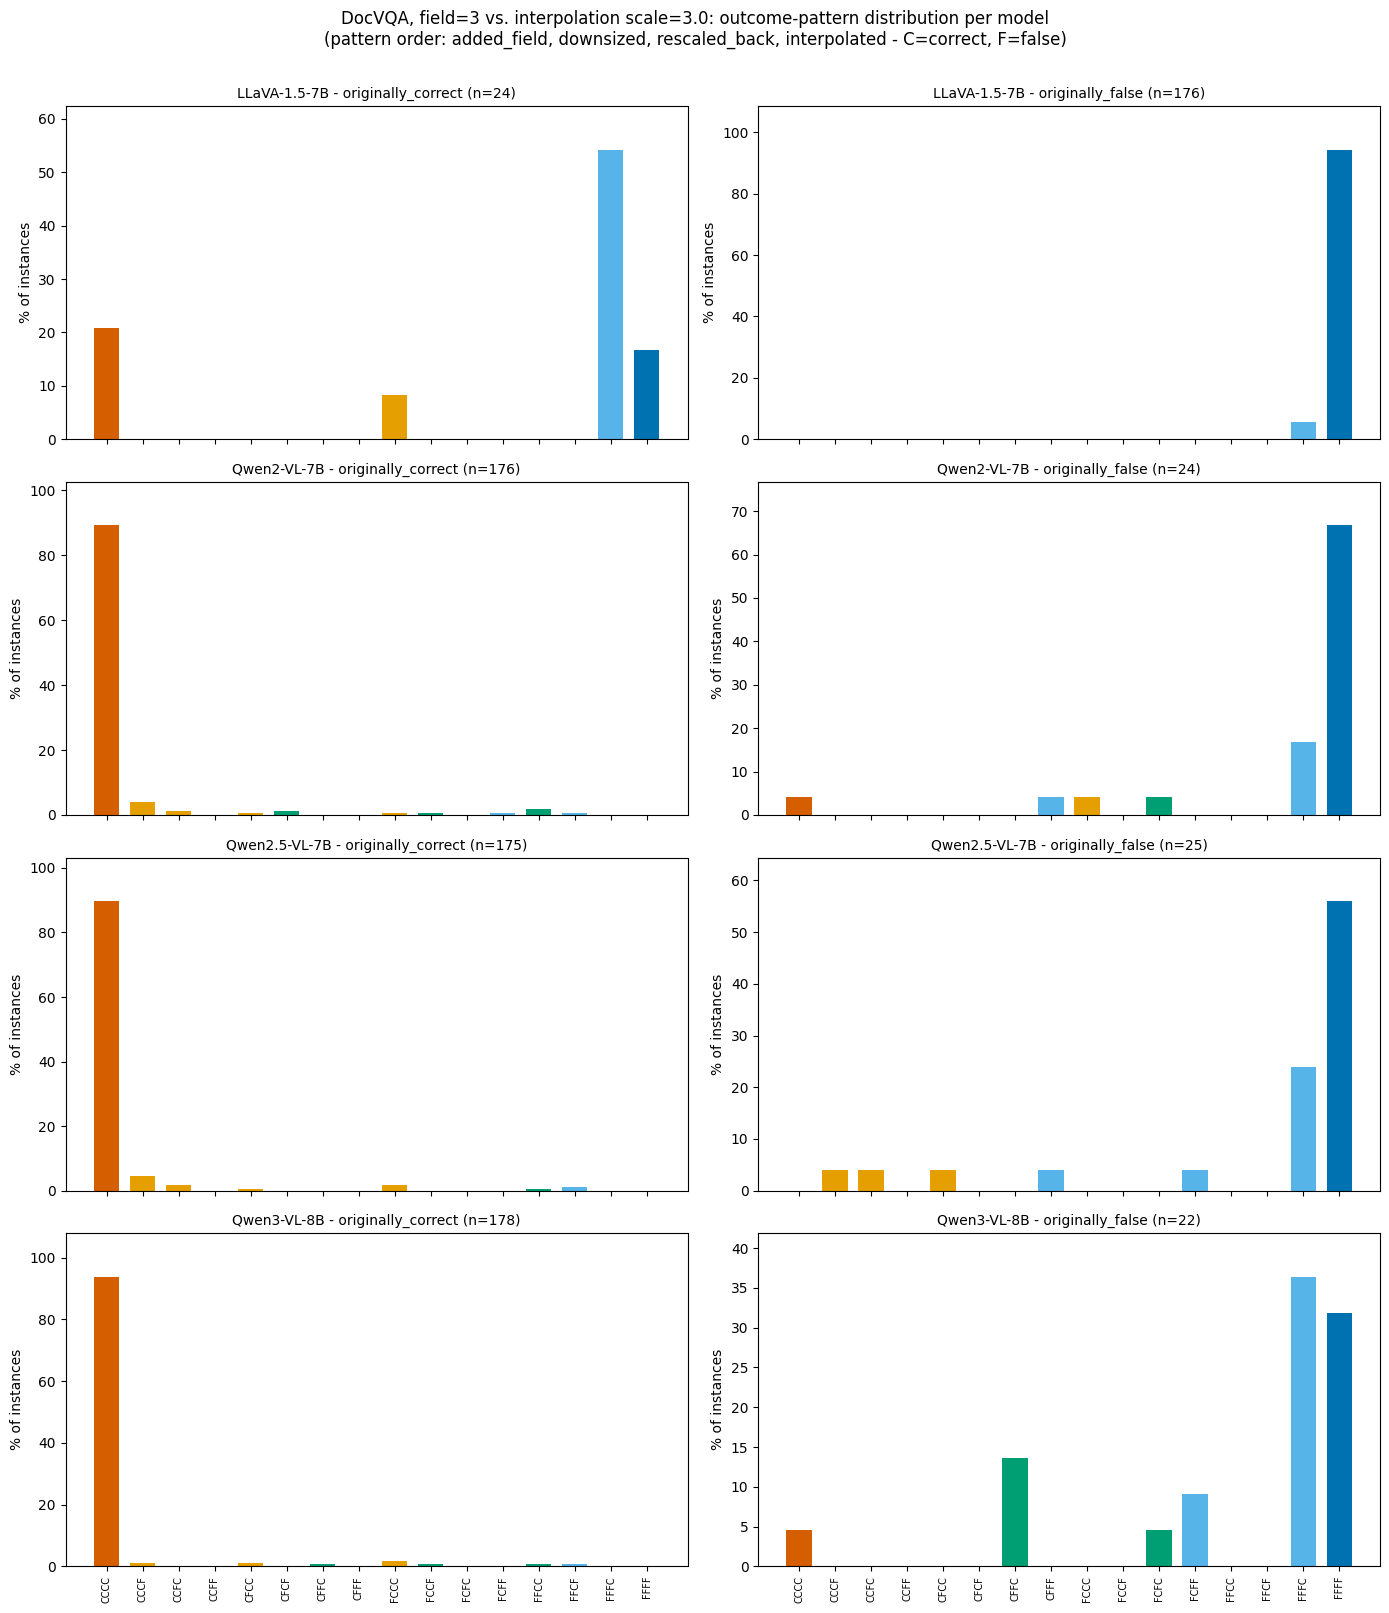

In [35]:
PATTERN_COLOR = {
    0: "#0072B2",  # 0 experiments correct
    1: "#56B4E9",
    2: "#009E73",
    3: "#E69F00",
    4: "#D55E00",  # all 4 experiments correct
}

def bar_colors(patterns):
    return [PATTERN_COLOR[p.count("C")] for p in patterns]


fig, axes = plt.subplots(len(MODELS), 2, figsize=(14, 4 * len(MODELS)), sharex=True)

for row, (_, _, display) in enumerate(MODELS):
    for col, group in enumerate(BASELINE_GROUPS):
        ax = axes[row, col]
        pct = summary_table.loc[(display, group)]
        ax.bar(ALL_PATTERNS, pct.values, color=bar_colors(ALL_PATTERNS), width=0.7)
        n = int(group_totals.loc[(display, group)])
        ax.set_title(f"{display} - {group} (n={n})", fontsize=10)
        ax.set_ylabel("% of instances")
        ax.tick_params(axis="x", rotation=90, labelsize=7)
        ax.set_ylim(0, max(pct.values.max() * 1.15, 5))

fig.suptitle(
    "DocVQA, field=3 vs. interpolation scale=3.0: outcome-pattern distribution per model\n"
    "(pattern order: added_field, downsized, rescaled_back, interpolated - C=correct, F=false)",
    fontsize=12, y=1.005,
)
fig.tight_layout()
plt.show()

## Aggregate view: how many of the 4 experiments stay correct?

Collapses each 16-way pattern down to "number of the 4 experiments still correct" (0-4), which is
easier to read at a glance than the full 16-pattern breakdown.

In [36]:
instance_df["n_correct"] = instance_df[EXPERIMENTS].eq(1.0).sum(axis=1)

agg = (
    instance_df.groupby(["model", "baseline_group", "n_correct"])
    .size()
    .rename("count")
    .reset_index()
)
agg_pct = agg.pivot_table(index=["model", "baseline_group"], columns="n_correct", values="count", fill_value=0)
agg_pct = agg_pct.div(agg_pct.sum(axis=1), axis=0) * 100
agg_pct.columns = [f"{c}/4 correct" for c in agg_pct.columns]
agg_pct.round(1)

0/4 correct  1/4 correct  2/4 correct  3/4 correct  4/4 correct
model         baseline_group                                                                     
LLaVA-1.5-7B  originally_correct         16.7         54.2          0.0          8.3         20.8
              originally_false           94.3          5.7          0.0          0.0          0.0
Qwen2-VL-7B   originally_correct          0.0          1.1          3.4          6.2         89.2
              originally_false           66.7         20.8          4.2          4.2          4.2
Qwen2.5-VL-7B originally_correct          0.0          1.1          0.6          8.6         89.7
              originally_false           56.0         32.0          0.0         12.0          0.0
Qwen3-VL-8B   originally_correct          0.0          0.6          1.7          3.9         93.8
              originally_false           31.8         45.5         18.2          0.0          4.5